# Why This Action? — MVP ejecutable

**Recomendar una acción con un modelo causal incierto, y decir cuánto confiar en ella.**

Este cuaderno corre de principio a fin sobre el ejemplo de juguete perioperatorio (Age, HbA1c, eGFR, Hb, SBP). Cada sección tiene cuatro partes:

1. **Qué hace** la celda y por qué existe.
2. **Literatura**: qué leer (con sección exacta) y el **gap declarado** por esos autores que la celda ataca.
3. **Cómo leer el código**.
4. El código y su resultado.

## Mapa

| § | Pieza | Capa de error | Frontera que ataca |
|---|---|---|---|
| 1 | El mundo verdadero y el paciente | — | — |
| 2 | La caja negra, con contador de consultas | — | F4 |
| 3 | Motor contrafactual con bloqueo de flechas | — | F6 |
| 4 | Incertidumbre del grafo | **Capa 1** | F1 |
| 5 | Incertidumbre de los mecanismos | **Capa 2** | F2 |
| 6 | Validez robusta y probabilidad de éxito | 1 + 2 | F2 |
| 7 | Optimización bayesiana compuesta | — | F4 |
| 8 | Certificación y poda | — | F7 |
| 9 | Probabilidad de éxito por capas y preguntas Q1–Q3 | 1 + 2 + experto | F3, F5 |
| 10 | Frontera confianza vs costo y plan B (Q4) | todas | F3 |
| 11 | Conformal prediction: mecanismos, clasificador, presupuesto | **Capas 2 y 3** | F3 |
| 12 | Calibración: ¿lo que decimos se cumple? | todas | F3 |
| 13 | Resumen y pendientes | | |

## Qué es y qué no es este MVP

- **Es** una implementación mínima que corre, con datos sintéticos donde conocemos la verdad, para mostrar que las piezas encajan.
- **No es** el experimento del paper. Las cifras son de **un ejemplo ilustrativo** con una sola semilla.
- Las simplificaciones están listadas en la sección 13.

## 1 · El mundo verdadero y el paciente

**Qué hace.** Define el modelo causal verdadero (con ruido aditivo), el logit verdadero de "apto para cirugía" y el paciente del ejemplo. En la vida real nada de esto se conoce: aquí existe solo para poder comprobar al final si lo que decimos se cumple.

**Literatura**
- [*Algorithmic Recourse: from Counterfactual Explanations to Interventions*](https://arxiv.org/abs/2002.06278) (Karimi, Schölkopf, Valera, FAccT 2021): **§3–§4**, la formulación con modelos de ruido aditivo.
- [*Algorithmic Recourse under Imperfect Causal Knowledge*](https://arxiv.org/abs/2006.06831) (NeurIPS 2020): **Apéndice E.1.2**, su caso semisintético de préstamos, que es el molde de este tipo de ejemplo.

**Gap declarado.** [MINT](https://arxiv.org/abs/2002.06278) (§6) reconoce que su supuesto principal es disponer del modelo verdadero. Todo lo que sigue es para no necesitarlo.

**Cómo leer el código.** `W_TRUE[j, k]` es el peso de la flecha k → j. `sample_world` genera personas recorriendo las variables en orden causal. Los pesos y el paciente son los de las diapositivas; el margen verdadero del paciente es −2 (no apto).

In [1]:
import numpy as np, matplotlib.pyplot as plt, warnings, time
from collections import Counter
from scipy import stats
from scipy.stats import norm
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, DotProduct, WhiteKernel, ConstantKernel as Const
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

VARS = ["Age", "HbA1c", "eGFR", "Hb", "SBP"]          # orden causal (lo da el experto)
IDX = {v: i for i, v in enumerate(VARS)}

# ---- El mundo verdadero (solo existe porque es un ejemplo sintético) ----
TRUE_EDGES = {("Age", "eGFR"): -0.5, ("HbA1c", "eGFR"): -6.0, ("eGFR", "Hb"): 0.06,
              ("Age", "Hb"): -0.02, ("Hb", "SBP"): 6.0}
INTERCEPT = {"Age": 62.0, "HbA1c": 7.5, "eGFR": 140.0, "Hb": 8.56, "SBP": 87.0}
NOISE_SD  = {"Age": 10.0, "HbA1c": 1.2, "eGFR": 8.0, "Hb": 0.8, "SBP": 10.0}
BETA = np.array([-0.03, -1.1, 0.02, 0.8, -0.08]); B0 = 11.89   # logit verdadero de "apto para cirugía"

def W_from_edges(edges):
    """Matriz de pesos: W[j, k] = peso de la flecha k -> j."""
    W = np.zeros((5, 5))
    for (k, j), w in edges.items(): W[IDX[j], IDX[k]] = w
    return W
W_TRUE = W_from_edges(TRUE_EDGES)

def sample_world(n, rng):
    """Genera n personas del modelo causal verdadero (ruido aditivo)."""
    X = np.zeros((n, 5))
    for j, v in enumerate(VARS):
        X[:, j] = INTERCEPT[v] + X @ W_TRUE[j] + NOISE_SD[v] * rng.standard_normal(n)
    return X

def true_logit(X): return B0 + X @ BETA
sigmoid = lambda z: 1 / (1 + np.exp(-z))

x0 = np.array([68.0, 8.5, 55.0, 10.5, 150.0])          # el paciente del ejemplo (valores ilustrativos)
print("Paciente:", dict(zip(VARS, x0)), "| margen verdadero:", round(float(true_logit(x0[None])[0]), 3))

Paciente: {'Age': np.float64(68.0), 'HbA1c': np.float64(8.5), 'eGFR': np.float64(55.0), 'Hb': np.float64(10.5), 'SBP': np.float64(150.0)} | margen verdadero: -2.0


## 2 · La caja negra

**Qué hace.** Entrena el modelo de riesgo "del hospital" (una red neuronal) y lo encierra en una clase que solo deja **consultar** su margen y **cuenta cada consulta**. El margen es logit(probabilidad) − logit(umbral): positivo significa apto.

**Literatura**
- [*A Survey of Algorithmic Recourse*](https://doi.org/10.1145/3527848) (Karimi y otros, ACM CSUR 2022): **§4.1.4 Access**.

**Gap declarado.** El [survey](https://doi.org/10.1145/3527848) dice que es poco probable que una organización entregue datos, parámetros o "siquiera una API sin límite de consultas". Los métodos con garantías de la línea de Karimi (SMT, MILP) necesitan ver el modelo por dentro; [NeurIPS 2020](https://arxiv.org/abs/2006.06831) necesita gradientes o fuerza bruta. Por eso el número de consultas es la moneda de este cuaderno.

**Cómo leer el código.** Nada del resto del cuaderno toca `clf` directamente para buscar planes: todo pasa por `BlackBox.margin`. Cada tarea crea su propio contador para que se vea cuánto costó.

In [2]:
rng = np.random.default_rng(7)
X_bank = sample_world(6000, rng)                         # datos con los que "el hospital" entrenó su modelo
y_bank = rng.random(6000) < sigmoid(true_logit(X_bank))
scaler = StandardScaler().fit(X_bank)
clf = MLPClassifier(hidden_layer_sizes=(16, 16), max_iter=3000, random_state=0).fit(scaler.transform(X_bank), y_bank)

class BlackBox:
    """Lo único que vemos del modelo: una consulta devuelve su margen. Cuenta cada consulta."""
    def __init__(self, tau=0.5): self.n = 0; self.tau = tau
    def margin(self, X):
        X = np.atleast_2d(X); self.n += len(X)
        p = np.clip(clf.predict_proba(scaler.transform(X))[:, 1], 1e-6, 1 - 1e-6)
        return np.log(p / (1 - p)) - np.log(self.tau / (1 - self.tau))

bb = BlackBox()
print("Margen del paciente según la caja negra:", round(float(bb.margin(x0)[0]), 3), "(negativo = no apto)")
print("Exactitud de la caja negra en sus datos:", round(clf.score(scaler.transform(X_bank), y_bank), 3))

Margen del paciente según la caja negra: -1.862 (negativo = no apto)
Exactitud de la caja negra en sus datos: 0.781


## 3 · Motor contrafactual con bloqueo de flechas

**Qué hace.** Dado un paciente, un conjunto de versiones del modelo causal y un conjunto de planes, calcula cómo quedaría el paciente después de cada plan en cada versión. Un plan es `[cambio en HbA1c, cambio en Hb, bloquear Hb → SBP]`.

**Literatura**
- [MINT](https://arxiv.org/abs/2002.06278) (FAccT 2021): **§4**, abducción-acción-predicción e intervenciones duras y aditivas.
- [*On the Adversarial Robustness of Causal Algorithmic Recourse*](https://arxiv.org/abs/2112.11313) ([ICML 2022](https://arxiv.org/abs/2112.11313)): **§3**, intervenciones aditivas.

**Gap declarado.** [MINT](https://arxiv.org/abs/2002.06278) (§6) deja para trabajo futuro intervenciones más ricas que fijar o sumar un valor (menciona las "fat-hand"). El **bloqueo de una flecha** es un tipo de acción que esa línea no contempla: el hijo sigue viendo el valor factual del padre, como un fármaco que impide que un cambio se propague.

**Cómo leer el código.** Con mecanismos lineales de ruido aditivo, la abducción se simplifica: el ruido del paciente no cambia, así que basta propagar la **desviación** respecto al paciente factual. `dev[:, :, j]` es cuánto se mueve la variable j. La línea `contrib[:, :, KB] *= (1 - blocked)` es el bloqueo. Todo está vectorizado sobre planes y versiones.

**Chequeo de cordura.** Con el modelo causal y el logit verdaderos debe salir el plan de las diapositivas (costo ≈ 1.299).

In [3]:
H_RANGE, B_RANGE = (-1.5, 0.0), (0.0, 2.0)               # cuánto se puede bajar HbA1c / subir Hb
BLOCK_EDGE = ("Hb", "SBP")                               # la flecha que un fármaco puede bloquear
JB, KB = IDX[BLOCK_EDGE[1]], IDX[BLOCK_EDGE[0]]

def plan_cost(plans):
    """plans: (C, 3) = [cambio HbA1c, cambio Hb, bloqueo 0/1]. El bloqueo no tiene costo en el ejemplo."""
    return np.abs(plans[:, 0]) + 0.5 * np.abs(plans[:, 1])

def make_worlds(W, block_ok=None, gid=None):
    """Un conjunto de versiones del mundo: pesos W (nW, 5, 5) y si el bloqueo funciona en cada una."""
    W = W if W.ndim == 3 else W[None]
    return dict(W=W, block_ok=np.ones(len(W)) if block_ok is None else np.asarray(block_ok, float), gid=gid)

def counterfactual(x0, worlds, plans, failed_edges=()):
    """Abducción-acción-predicción para modelos lineales de ruido aditivo.
    x0: (5,) paciente | worlds: versiones del modelo causal | plans: (C, 3)
    failed_edges: flechas que NO transmiten (preguntas tipo 'y si este mecanismo falla').
    Devuelve (C, nW, 5): el paciente después del plan, en cada versión."""
    W, C, nW = worlds["W"], len(plans), len(worlds["W"])
    delta = np.zeros((C, 5)); delta[:, IDX["HbA1c"]] = plans[:, 0]; delta[:, IDX["Hb"]] = plans[:, 1]
    keep = np.ones((5, 5))                               # keep[j, k] = 0 si la flecha k -> j no transmite
    for (k, j) in failed_edges: keep[IDX[j], IDX[k]] = 0
    blocked = plans[:, 2][:, None] * worlds["block_ok"][None, :]      # (C, nW): bloqueo pedido Y que funciona
    dev = np.zeros((C, nW, 5))                           # desviación respecto al paciente factual
    for j in range(5):                                   # en orden causal
        contrib = dev * (W[:, j, :] * keep[j])[None]     # (C, nW, 5): lo que llega de cada padre
        if j == JB: contrib[:, :, KB] *= (1 - blocked)   # la flecha bloqueada ve el valor factual del padre
        dev[:, :, j] = contrib.sum(-1) + delta[:, j, None]
    return x0 + dev

TRUE_WORLD = make_worlds(W_TRUE)

# --- Chequeo de cordura: con el modelo causal y el logit VERDADEROS debe salir el plan de las diapositivas ---
hs, bs = np.linspace(*H_RANGE, 301), np.linspace(*B_RANGE, 201)
grid = np.array([(h, b, k) for k in (0, 1) for h in hs for b in bs])
m = true_logit(counterfactual(x0, TRUE_WORLD, grid)[:, 0, :])
ok = m >= 0.05                                           # misma holgura que en el ejemplo de juguete
best = grid[ok][np.argmin(plan_cost(grid[ok]))]
print(f"Plan oráculo: HbA1c {best[0]:+.3f}, Hb {best[1]:+.2f}, bloqueo={bool(best[2])}, costo={plan_cost(best[None])[0]:.3f}")
print("(en las diapositivas: HbA1c -0.304, Hb +1.99, bloqueo, costo 1.299; hay varios planes con ese mismo costo)")

Plan oráculo: HbA1c -0.325, Hb +1.95, bloqueo=True, costo=1.300
(en las diapositivas: HbA1c -0.304, Hb +1.99, bloqueo, costo 1.299; hay varios planes con ese mismo costo)


## 4 · Capa 1: incertidumbre del grafo

**Qué hace.** Con 300 observaciones, re-estima el grafo en 400 remuestreos (bootstrap). La frecuencia de cada grafo es su peso w_g. El resultado no es *un* grafo, sino una distribución sobre grafos plausibles.

**Literatura**
- [*Your Assumed DAG is Wrong and Here's How To Deal With It*](https://arxiv.org/abs/2502.17030) (Padh, Li, Casolo, Kilbertus, 2025): cotas de una consulta causal sobre una colección de grafos. *Solo leímos el resumen.*
- [*Confidence Sets for Causal Orderings*](https://arxiv.org/abs/2305.14506) (Wang, Kolar, Drton, 2023): conjunto de órdenes causales con garantía. *Pendiente de leer.*
- [*DiBS: Differentiable Bayesian Structure Learning*](https://arxiv.org/abs/2105.11839) (Lorch y otros, NeurIPS 2021): distribución posterior sobre grafos. *Pendiente de leer.*
- [*Active Bayesian Causal Inference*](https://arxiv.org/abs/2206.02063) (Toth y otros, NeurIPS 2022): grafo y mecanismos inciertos a la vez para una consulta causal. *Pendiente de leer.*

**Gap declarado.** [NeurIPS 2020](https://arxiv.org/abs/2006.06831) (§8): "we have assumed a known causal graph and causal sufficiency"; con grafos parciales habría que restringirse a intervenciones identificables. [MINT](https://arxiv.org/abs/2002.06278) (§6) y el [survey](https://doi.org/10.1145/3527848) (§5.1) dicen lo mismo. La [posición de 2026](https://arxiv.org/abs/2603.28597) (§5) pide descubrimiento causal robusto. **Ningún paper de recourse que hayamos encontrado propaga el error del grafo hasta la recomendación.**

**Cómo leer el código.** `select_graph` es un sustituto deliberadamente simple de un método de descubrimiento causal: supone el **orden causal dado por el experto** y decide cada flecha con una prueba de significancia. `bootstrap_graphs` lo repite sobre remuestreos. Para el paper, esta función se reemplaza por un método serio; la interfaz (lista de grafos con pesos) queda igual.

**Qué mirar.** Qué flechas verdaderas aparecen siempre, cuáles a veces, y qué flechas falsas se cuelan.

In [4]:
rng = np.random.default_rng(1)
X_obs = sample_world(300, rng)                           # los datos observacionales que tenemos

def select_graph(X, alpha=0.01):
    """Dado el orden causal, cada variable se regresa sobre sus predecesoras y se conservan
    las flechas con coeficiente significativo. Devuelve el grafo como conjunto de flechas."""
    n, edges = len(X), []
    for j in range(1, 5):
        Z = np.column_stack([np.ones(n), X[:, :j]])
        beta, *_ = np.linalg.lstsq(Z, X[:, j], rcond=None)
        res = X[:, j] - Z @ beta
        se = np.sqrt(res @ res / (n - Z.shape[1]) * np.diag(np.linalg.inv(Z.T @ Z)))
        p = 2 * stats.t.sf(np.abs(beta / se), n - Z.shape[1])
        edges += [(VARS[k], VARS[j]) for k in range(j) if p[k + 1] < alpha]
    return frozenset(edges)

def bootstrap_graphs(X, B=400, rng=rng):
    """Re-estima el grafo en B remuestreos. La frecuencia de cada grafo es su peso w_g."""
    cnt = Counter(select_graph(X[rng.integers(0, len(X), len(X))]) for _ in range(B))
    return [(g, c / B) for g, c in cnt.most_common()]

graphs = bootstrap_graphs(X_obs)
edge_freq = Counter()
for g, w in graphs:
    for e in g: edge_freq[e] += w
print(f"{len(graphs)} grafos distintos en 400 remuestreos. Los 5 más frecuentes:")
for g, w in graphs[:5]:
    extra = sorted(set(g) - set(TRUE_EDGES)); miss = sorted(set(TRUE_EDGES) - set(g))
    print(f"  w={w:.3f} | sobran {extra or '-'} | faltan {miss or '-'}")
print("\nFrecuencia de cada flecha (las verdaderas marcadas con *):")
for e, f in sorted(edge_freq.items(), key=lambda t: (-t[1], t[0])):
    print(f"  {'*' if e in TRUE_EDGES else ' '} {e[0]:>5} -> {e[1]:<5} {f:.3f}")

16 grafos distintos en 400 remuestreos. Los 5 más frecuentes:
  w=0.615 | sobran - | faltan -
  w=0.125 | sobran [('Age', 'HbA1c')] | faltan -
  w=0.100 | sobran - | faltan [('Age', 'Hb')]
  w=0.077 | sobran [('Age', 'SBP')] | faltan -
  w=0.018 | sobran [('HbA1c', 'SBP')] | faltan -

Frecuencia de cada flecha (las verdaderas marcadas con *):
  *   Age -> eGFR  1.000
  *    Hb -> SBP   1.000
  * HbA1c -> eGFR  1.000
  *  eGFR -> Hb    1.000
  *   Age -> Hb    0.880
      Age -> HbA1c 0.160
      Age -> SBP   0.105
    HbA1c -> SBP   0.025
    HbA1c -> Hb    0.015
     eGFR -> SBP   0.013


## 5 · Capa 2: incertidumbre de los mecanismos

**Qué hace.** Construye las **versiones del modelo causal**: para cada una sortea un grafo según w_g y re-estima las ecuaciones en un remuestreo de los datos. Cada versión es un mundo compatible con lo observado.

**Literatura**
- [NeurIPS 2020](https://arxiv.org/abs/2006.06831): **§3** (sin las ecuaciones verdaderas no hay garantía de recourse) y **§4** (un proceso gaussiano por mecanismo).
- [*Explainable AI is Causality in Disguise*](https://arxiv.org/abs/2603.28597) (Karimi, 2026): **§4.1**.

**Gap declarado.** [NeurIPS 2020](https://arxiv.org/abs/2006.06831) modela esta capa, pero atada a procesos gaussianos y resumida en un parámetro γ que no es una probabilidad. La [posición de 2026](https://arxiv.org/abs/2603.28597) (§4.1) propone medir la estabilidad de la explicación ante perturbaciones del modelo causal estimado, sin dar método.

**Cómo leer el código.** `fit_mechanisms` es mínimos cuadrados por variable sobre sus padres. `sample_worlds` acepta además `fail_prob` y `block_fail`: son **supuestos del experto** (probabilidad de que un mecanismo no opere en este paciente o de que el fármaco no bloquee). No salen de los datos y se usan más adelante, separados de la parte estadística.

**Qué mirar.** La dispersión de cada peso entre versiones frente al valor verdadero.

In [5]:
def fit_mechanisms(X, graph):
    """Mínimos cuadrados de cada variable sobre sus padres en el grafo. Devuelve W (5, 5)."""
    W = np.zeros((5, 5))
    for j in range(5):
        pa = sorted(IDX[k] for (k, jj) in graph if IDX[jj] == j)
        if pa:
            Z = np.column_stack([np.ones(len(X)), X[:, pa]])
            W[j, pa] = np.linalg.lstsq(Z, X[:, j], rcond=None)[0][1:]
    return W

def sample_worlds(X, graphs, n_worlds, rng, fail_prob=None, block_fail=0.0):
    """Cada versión = un grafo sorteado según w_g + mecanismos re-estimados en un remuestreo.
    fail_prob / block_fail: supuestos del EXPERTO (no salen de los datos): probabilidad de que un
    mecanismo no opere en este paciente, o de que el fármaco que bloquea no funcione."""
    probs = np.array([w for _, w in graphs]); gid = rng.choice(len(graphs), n_worlds, p=probs / probs.sum())
    W = np.stack([fit_mechanisms(X[rng.integers(0, len(X), len(X))], graphs[g][0]) for g in gid])
    for (k, j), pr in (fail_prob or {}).items():
        W[rng.random(n_worlds) < pr, IDX[j], IDX[k]] = 0.0
    return make_worlds(W, rng.random(n_worlds) >= block_fail, gid)

rng = np.random.default_rng(2)
WORLDS = sample_worlds(X_obs, graphs, 120, rng)          # incertidumbre ESTADÍSTICA: grafo + mecanismos
print("Versiones del modelo causal:", len(WORLDS["W"]), "| grafos distintos entre ellas:", len(set(WORLDS["gid"])))
print("\nPeso estimado de cada flecha verdadera (media ± desviación entre versiones) vs verdad:")
for (k, j), w in TRUE_EDGES.items():
    v = WORLDS["W"][:, IDX[j], IDX[k]]
    print(f"  {k:>5} -> {j:<5} {v.mean():+.3f} ± {v.std():.3f}   (verdad {w:+.3f})")

Versiones del modelo causal: 120 | grafos distintos entre ellas: 10

Peso estimado de cada flecha verdadera (media ± desviación entre versiones) vs verdad:
    Age -> eGFR  -0.621 ± 0.044   (verdad -0.500)
  HbA1c -> eGFR  -6.194 ± 0.355   (verdad -6.000)
   eGFR -> Hb    +0.061 ± 0.005   (verdad +0.060)
    Age -> Hb    -0.019 ± 0.009   (verdad -0.020)
     Hb -> SBP   +5.289 ± 0.577   (verdad +6.000)


## 6 · Validez robusta y probabilidad de éxito

**Qué hace.** Define las dos medidas centrales:
- **Margen robusto:** el (k+1)-ésimo margen más pequeño entre las versiones, con k = ⌊ε · número de versiones⌋. Si es ≥ 0, el plan funciona en al menos (1 − ε) de las versiones. El usuario elige ε.
- **Probabilidad de éxito:** la fracción de versiones donde el plan funciona, con intervalo de Wilson.

Después muestra el problema: el plan más barato según **una sola** estimación del modelo causal.

**Literatura**
- [NeurIPS 2020](https://arxiv.org/abs/2006.06831): **§4** y **Figura 2(c)**, su intercambio validez–costo con γ.
- [*BO of Risk Measures*](https://arxiv.org/abs/2007.05554) (Cakmak y otros, NeurIPS 2020): optimizar un cuantil en vez de un promedio.
- [ICML 2022](https://arxiv.org/abs/2112.11313): **§4**, prueba de que el recourse de costo mínimo es frágil.

**Gap declarado.** El criterio de [NeurIPS 2020](https://arxiv.org/abs/2006.06831) (media − γ · dispersión ≥ umbral) no dice qué probabilidad de éxito garantiza un γ dado. Aquí el nivel de riesgo es explícito.

**Qué mirar.** En cuántas versiones funciona el plan ingenuo, y cuántas consultas costó encontrarlo recorriendo una malla.

In [6]:
def robust_margin(M, eps):
    """M: (C, nW) márgenes por versión. Devuelve el (k+1)-ésimo más pequeño, k = floor(eps * nW),
    y en qué versión ocurre. Si es >= 0, el plan funciona en al menos (1 - eps) de las versiones."""
    k = int(np.floor(eps * M.shape[1]))
    idx = np.argpartition(M, k, axis=1)[:, k]
    return M[np.arange(len(M)), idx], idx

def success_prob(m):
    """Probabilidad de éxito = fracción de versiones con margen >= 0, con intervalo de Wilson al 95 %."""
    n, p = len(m), float(np.mean(m >= 0)); z = 1.96
    c = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return p, max(0, c - h), min(1, c + h)

# Ejemplo: el plan más barato si creyéramos ciegamente en UNA estimación del modelo causal
bb_audit = BlackBox()
W_point = make_worlds(fit_mechanisms(X_obs, graphs[0][0]))
coarse = grid[::7]
m_pt = bb_audit.margin(counterfactual(x0, W_point, coarse)[:, 0, :])
naive = coarse[m_pt >= 0][np.argmin(plan_cost(coarse[m_pt >= 0]))]
p, lo, hi = success_prob(bb_audit.margin(counterfactual(x0, WORLDS, naive[None])[0]))
print(f"Plan ingenuo (una sola estimación): HbA1c {naive[0]:+.3f}, Hb {naive[1]:+.2f}, bloqueo={bool(naive[2])}, costo={plan_cost(naive[None])[0]:.3f}")
print(f"  ...pero en las 120 versiones plausibles solo funciona en {100 * p:.0f} %  (IC 95 %: {100 * lo:.0f} a {100 * hi:.0f} %)")
print(f"Encontrarlo así costó {bb_audit.n:,} consultas a la caja negra. Por eso hace falta un sustituto.")

Plan ingenuo (una sola estimación): HbA1c -0.295, Hb +1.74, bloqueo=True, costo=1.165
  ...pero en las 120 versiones plausibles solo funciona en 61 %  (IC 95 %: 52 a 69 %)
Encontrarlo así costó 17,406 consultas a la caja negra. Por eso hace falta un sustituto.


## 7 · Optimización bayesiana compuesta

**Qué hace.** Busca el plan más barato que sea válido al riesgo ε, gastando pocas consultas.

**La idea.** Hay dos funciones muy distintas:
- la caja negra h(x): cara y desconocida;
- el modelo causal en todas sus versiones: barato y conocido por nosotros.

Un **único** proceso gaussiano aprende h. El modelo causal se aplica por fuera. Así, una consulta mejora la predicción para todas las versiones, todos los planes y todos los bloqueos a la vez.

**Literatura**
- [*Bayesian Optimization of Composite Functions*](https://arxiv.org/abs/1906.01537) (Astudillo y Frazier, ICML 2019): modelar solo la parte desconocida.
- [*Bayesian Optimization with Unknown Constraints*](https://arxiv.org/abs/1403.5607) (Gelbart y otros, 2014): mejora esperada ponderada por probabilidad de factibilidad.
- [Cakmak y otros (2020)](https://arxiv.org/abs/2007.05554): BO sobre medidas de riesgo.
- [NeurIPS 2020](https://arxiv.org/abs/2006.06831): **§6**, para ver contra qué se compara (gradiente o fuerza bruta).

**Gap declarado.** [NeurIPS 2020](https://arxiv.org/abs/2006.06831) (§6) optimiza con gradiente si el clasificador es diferenciable y, si no, con fuerza bruta sobre acciones discretizadas. [ICML 2022](https://arxiv.org/abs/2112.11313) solo resuelve clasificadores lineales o diferenciables. Ningún paper de la lista de Karimi usa optimización bayesiana.

**Cómo leer el código** (`solve_bo`)
1. `assess()`: ajusta el sustituto, predice el margen de cada candidato en cada versión, toma la **versión que ata** la restricción (la del margen robusto) y calcula ahí la probabilidad de validez `pf`.
2. Adquisición: si ya hay un plan probablemente válido de costo c*, `(c* − costo)⁺ · pf` (mejora factible esperada); si no hay ninguno, solo `pf`.
3. Se consulta la caja negra **una vez**, en el punto de la versión que ata para el candidato elegido.
4. Certificación: el plan más barato probablemente válido se comprueba con la caja negra real en todas las versiones. Si falla, el sustituto aprende de las versiones más difíciles y se reintenta.

**Qué mirar.** Consultas de búsqueda y de certificación, frente a las de la malla de la sección 6.

In [7]:
def make_gp():
    kernel = Const(1.0) * DotProduct(sigma_0=1.0) + Const(0.5) * RBF(length_scale=2.0) + WhiteKernel(1e-3)
    return GaussianProcessRegressor(kernel=kernel, normalize_y=True, random_state=0)

def gp_mean(gp, X, chunk=40000):
    return np.concatenate([gp.predict(scaler.transform(X[i:i + chunk])) for i in range(0, len(X), chunk)])

def thin(X, y, cap=220, seed=0):
    """Si hay demasiadas consultas guardadas, el sustituto se ajusta con las últimas 80 y una muestra del resto."""
    if len(X) <= cap: return X, y
    idx = np.r_[np.random.default_rng(seed).choice(len(X) - 80, cap - 80, replace=False), np.arange(len(X) - 80, len(X))]
    return X[idx], y[idx]

def sample_plans(n, rng, around=None, scale=0.12):
    if around is None:
        return np.column_stack([rng.uniform(*H_RANGE, n), rng.uniform(*B_RANGE, n), rng.integers(0, 2, n)])
    return np.column_stack([np.clip(around[0] + scale * rng.standard_normal(n), *H_RANGE),
                            np.clip(around[1] + scale * rng.standard_normal(n), *B_RANGE), np.full(n, around[2])])

def solve_bo(x0, worlds, eps, bb, n_iter=40, n_cand=1200, failed_edges=(), data=None, seed=0, verbose=True):
    """Optimización bayesiana compuesta.
    - UN proceso gaussiano aprende el margen de la caja negra h(x).
    - El modelo causal (todas sus versiones) se aplica por fuera: es barato y conocido.
    - Cada consulta a la caja negra mejora la predicción para TODAS las versiones y planes.
    Devuelve el plan certificado (o None) y un dict con consultas, historial, datos y sustituto."""
    rng = np.random.default_rng(seed); nW = len(worlds["W"]); q0 = bb.n
    cf = lambda P: counterfactual(x0, worlds, P, failed_edges)                 # (C, nW, 5)
    if data is None:                                                            # diseño inicial: 1 + 8 puntos
        P0 = sample_plans(8, rng); X0 = np.vstack([x0[None], cf(P0)[np.arange(8), rng.integers(0, nW, 8)]])
        data = [X0, bb.margin(X0)]
    Xq, yq = data
    corners = np.array([[h, b, k] for h in H_RANGE for b in B_RANGE for k in (0, 1)])
    cands = np.vstack([corners, sample_plans(n_cand, rng)]); costs = plan_cost(cands)

    def assess():
        """Con el sustituto actual: para cada candidato, la versión que ata la restricción y su prob. de validez."""
        Xt, yt = thin(Xq, yq)
        gp = make_gp().fit(scaler.transform(Xt), yt)
        Xc = cf(cands)
        mu = gp_mean(gp, Xc.reshape(-1, 5)).reshape(len(cands), nW)
        mu_b, w_b = robust_margin(mu, eps)
        Xb = Xc[np.arange(len(cands)), w_b]
        sd_b = gp.predict(scaler.transform(Xb), return_std=True)[1]
        return Xc, Xb, norm.cdf(mu_b / np.maximum(sd_b, 1e-6))

    hist = []
    for it in range(n_iter):                                                    # ---- búsqueda ----
        Xc, Xb, pf = assess()
        feas = pf >= 0.9
        c_star = costs[feas].min() if feas.any() else np.inf
        acq = pf if not np.isfinite(c_star) else np.maximum(c_star - costs, 0) * pf   # mejora factible esperada
        if acq.max() <= 1e-9: acq = pf * (1 - pf)                               # nada mejora: reducir la duda
        i = int(np.argmax(acq))
        Xq = np.vstack([Xq, Xb[i][None]]); yq = np.append(yq, bb.margin(Xb[i]))  # UNA consulta
        hist.append((bb.n - q0, c_star))
        if it == n_iter // 2 and feas.any():                                    # refinar cerca del mejor
            inc = cands[feas][np.argmin(costs[feas])]
            cands = np.vstack([cands, sample_plans(n_cand // 2, rng, around=inc)]); costs = plan_cost(cands)

    best, q_search = None, bb.n - q0
    for _ in range(8):                                                          # ---- certificación ----
        Xc, Xb, pf = assess()
        feas = pf >= 0.9
        if not feas.any(): break
        i = int(np.flatnonzero(feas)[np.argmin(costs[feas])])
        mi = bb.margin(Xc[i])                                                   # caja negra real, todas las versiones
        low = np.argsort(mi)[: max(8, int(2 * eps * nW))]                       # el sustituto aprende de las más difíciles
        Xq = np.vstack([Xq, Xc[i][low]]); yq = np.append(yq, mi[low])
        if robust_margin(mi[None], eps)[0][0] >= 0: best = cands[i].copy(); break
    info = dict(q_search=q_search, q_cert=bb.n - q0 - q_search, hist=hist, data=[Xq, yq],
                gp=make_gp().fit(scaler.transform(thin(Xq, yq)[0]), thin(Xq, yq)[1]))
    if verbose:
        if best is None: print("No se certificó ningún plan dentro de los límites de acción.")
        else: print(f"Plan certificado: HbA1c {best[0]:+.3f}, Hb {best[1]:+.2f}, bloqueo={bool(best[2])}, "
                    f"costo={plan_cost(best[None])[0]:.3f} | consultas: {q_search} de búsqueda + {info['q_cert']} de certificación")
    return best, info

EPS = 0.10                                               # el usuario tolera que falle en 10 % de las versiones
bb = BlackBox(); t0 = time.time()
plan, info = solve_bo(x0, WORLDS, EPS, bb)
print(f"Tiempo: {time.time() - t0:.0f} s")
print(f"Referencia: recorrer la malla completa con la caja negra real costaría {len(grid) * len(WORLDS['W']):,} consultas.")

Plan certificado: HbA1c -0.166, Hb +2.00, bloqueo=True, costo=1.166 | consultas: 49 de búsqueda + 120 de certificación
Tiempo: 8 s
Referencia: recorrer la malla completa con la caja negra real costaría 14,520,240 consultas.


## 8 · Certificación y poda

**Qué hace.** Quita cada pieza del plan y comprueba con la caja negra real si sigue siendo válido. Lo que sobra se elimina.

**Literatura**
- [*Beyond Explainable AI (XAI)*](https://arxiv.org/abs/2602.24176) (Afroogh y otros, 2026): **§3.4** y **§4.1**, pasar de explicar a verificar y certificar.
- [MINT](https://arxiv.org/abs/2002.06278): **§4**, minimalidad de la intervención.

**Gap declarado.** [Beyond XAI](https://arxiv.org/abs/2602.24176) propone la verificación como paradigma, pero no da métodos para recomendaciones de acción.

**Qué mirar.** El margen robusto sin cada pieza (si es negativo, la pieza es necesaria), la curva de búsqueda y cómo se reparte el margen del plan entre las versiones.

  sin cambio de HbA1c  : margen robusto -0.119 -> necesaria
  sin cambio de Hb     : margen robusto -1.634 -> necesaria
  sin bloqueo Hb->SBP  : margen robusto -1.393 -> necesaria

Plan final: HbA1c -0.166, Hb +2.00, bloqueo=True, costo=1.166


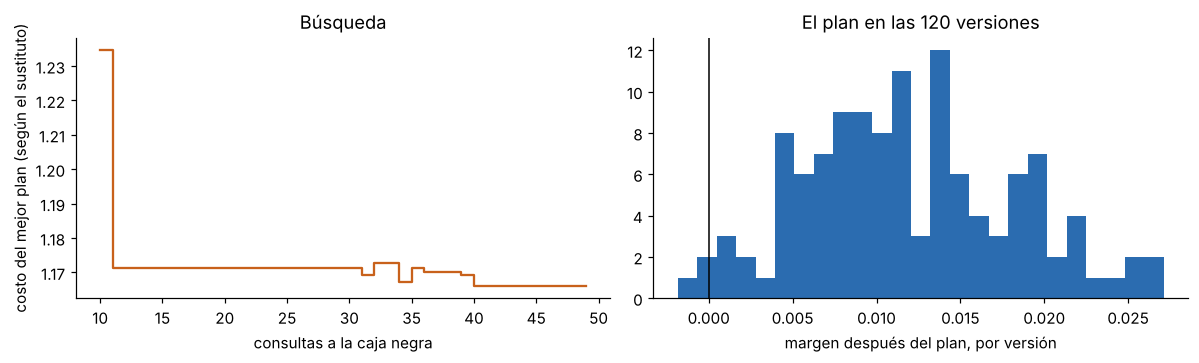

In [8]:
def certified(plan, eps, bb, worlds=None, failed_edges=()):
    m = bb.margin(counterfactual(x0, WORLDS if worlds is None else worlds, plan[None], failed_edges)[0])
    return robust_margin(m[None], eps)[0][0] >= 0, m

def prune(plan, eps, bb, worlds=None):
    """Quita cada pieza del plan; si sigue siendo válido sin ella, la pieza sobra."""
    names, plan = ["cambio de HbA1c", "cambio de Hb", "bloqueo Hb->SBP"], plan.copy()
    for i, nm in enumerate(names):
        if plan[i] == 0: continue
        trial = plan.copy(); trial[i] = 0
        ok, m = certified(trial, eps, bb, worlds)
        print(f"  sin {nm:<17}: margen robusto {robust_margin(m[None], eps)[0][0]:+.3f} -> {'SOBRA' if ok else 'necesaria'}")
        if ok: plan = trial
    return plan

bb_cert = BlackBox()
plan = prune(plan, EPS, bb_cert)
ok, M_plan = certified(plan, EPS, bb_cert)
print(f"\nPlan final: HbA1c {plan[0]:+.3f}, Hb {plan[1]:+.2f}, bloqueo={bool(plan[2])}, costo={plan_cost(plan[None])[0]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
q, c = zip(*info["hist"]); ax[0].step(q, c, where="post", color="#C8611B")
ax[0].set(xlabel="consultas a la caja negra", ylabel="costo del mejor plan (según el sustituto)", title="Búsqueda")
ax[1].hist(M_plan, bins=25, color="#2B6CB0"); ax[1].axvline(0, color="k", lw=1)
ax[1].set(xlabel="margen después del plan, por versión", title="El plan en las 120 versiones"); plt.tight_layout(); plt.show()

## 9 · Probabilidad de éxito por capas, y las preguntas

**Qué hace.**
1. Mide la probabilidad de éxito del plan en **versiones nuevas**, añadiendo una capa de incertidumbre cada vez: solo mecanismos → + grafo (**estadística**) → + supuestos del experto (**total**).
2. Responde las preguntas: Q1 cuánto del cambio hay que lograr, Q2 qué pasa si un mecanismo no opera, Q3 qué pasa si el bloqueo falla.

**Literatura**
- [Posición 2026](https://arxiv.org/abs/2603.28597): **§4.1** y **Apéndice C (RQ3, RQ4, RQ6–RQ7)**.
- [ICML 2022](https://arxiv.org/abs/2112.11313): **Apéndice A**, su lista de fuentes de incertidumbre.

**Gap declarado.** La RQ4 pide cotas de cómo los errores del modelo causal afectan las tareas de XAI; la §4.1 propone análisis de sensibilidad. Ninguna de las dos se desarrolla. [NeurIPS 2020](https://arxiv.org/abs/2006.06831) entrega un plan con una cota agregada, sin decir de dónde viene el riesgo.

**Cómo leer el código.** `margins_real` consulta la caja negra (auditoría); `margins_surrogate` usa el sustituto ya entrenado y **no gasta consultas**. Se muestran las dos para ver cuánto se parecen. `EXPERT` contiene los supuestos ilustrativos del experto: 3 % de que cada mecanismo no opere y 3 % de que el bloqueo falle.

**Qué mirar.** Cuánto baja la probabilidad al añadir cada capa: eso es el **desglose** de la incertidumbre.

In [9]:
gp = info["gp"]                                          # el sustituto ya entrenado: preguntarle no cuesta consultas
bb_audit = BlackBox()
def margins_surrogate(plan, worlds, failed_edges=()):
    return gp.predict(scaler.transform(counterfactual(x0, worlds, plan[None], failed_edges)[0]))
def margins_real(plan, worlds, failed_edges=()):
    return bb_audit.margin(counterfactual(x0, worlds, plan[None], failed_edges)[0])

# Versiones NUEVAS (no usadas en la búsqueda), añadiendo una capa de incertidumbre cada vez
rng = np.random.default_rng(3); N = 400
g_top = graphs[0][0]
W_mech  = make_worlds(np.stack([fit_mechanisms(X_obs[rng.integers(0, 300, 300)], g_top) for _ in range(N)]))
W_stat  = sample_worlds(X_obs, graphs, N, rng)
EXPERT  = dict(fail_prob={("HbA1c", "eGFR"): 0.03, ("eGFR", "Hb"): 0.03}, block_fail=0.03)   # supuestos ilustrativos
W_total = sample_worlds(X_obs, graphs, N, rng, **EXPERT)

print("PROBABILIDAD DE ÉXITO DEL PLAN, capa por capa         caja negra real          | sustituto")
for nm, Wx in [("solo error de mecanismos (grafo fijo)", W_mech), ("+ error del grafo  -> ESTADÍSTICA", W_stat),
               ("+ supuestos del experto -> TOTAL", W_total)]:
    p, lo, hi = success_prob(margins_real(plan, Wx)); ps = success_prob(margins_surrogate(plan, Wx))[0]
    print(f"  {nm:<38} {p:.3f}  IC 95 % [{lo:.3f}, {hi:.3f}]  | {ps:.3f}")
p_stat = success_prob(margins_real(plan, W_stat))[0]; p_total = success_prob(margins_real(plan, W_total))[0]

print("\nQ1 · ¿Cuánto del cambio debo lograr? (calculado con el sustituto: cero consultas)")
for i, nm in [(0, "HbA1c"), (1, "Hb")]:
    if plan[i] == 0: continue
    for g in np.linspace(0, 1, 201):
        t = plan.copy(); t[i] *= g
        if robust_margin(margins_surrogate(t, WORLDS)[None], EPS)[0][0] >= 0: break
    print(f"  {nm}: al menos {100 * g:.1f} % del cambio planeado")
print("Q2 · ¿Y si un mecanismo no opera en este paciente?")
for e in [("HbA1c", "eGFR"), ("eGFR", "Hb")]:
    m = margins_real(plan, W_stat, failed_edges=[e])
    print(f"  falla {e[0]}->{e[1]}: éxito = {success_prob(m)[0]:.2f}, margen mediano {np.median(m):+.3f}")
if plan[2] == 1:
    t = plan.copy(); t[2] = 0; m = margins_real(t, W_stat)
    print(f"Q3 · ¿Y si el bloqueo falla?  éxito = {success_prob(m)[0]:.2f}, margen mediano {np.median(m):+.3f}")
print(f"\n(consultas de auditoría usadas en esta celda: {bb_audit.n:,})")

PROBABILIDAD DE ÉXITO DEL PLAN, capa por capa         caja negra real          | sustituto
  solo error de mecanismos (grafo fijo)  0.935  IC 95 % [0.906, 0.955]  | 0.938
  + error del grafo  -> ESTADÍSTICA      0.950  IC 95 % [0.924, 0.967]  | 0.955
  + supuestos del experto -> TOTAL       0.848  IC 95 % [0.809, 0.879]  | 0.853

Q1 · ¿Cuánto del cambio debo lograr? (calculado con el sustituto: cero consultas)
  HbA1c: al menos 98.5 % del cambio planeado


  Hb: al menos 100.0 % del cambio planeado
Q2 · ¿Y si un mecanismo no opera en este paciente?
  falla HbA1c->eGFR: éxito = 0.00, margen mediano -0.040
  falla eGFR->Hb: éxito = 0.00, margen mediano -0.051
Q3 · ¿Y si el bloqueo falla?  éxito = 0.00, margen mediano -1.276

(consultas de auditoría usadas en esta celda: 3,200)


## 10 · Frontera confianza vs costo, y plan B

**Qué hace.** Repite la búsqueda para varios niveles de confianza, ahora con la incertidumbre **total** (datos + experto), y mide el éxito de cada plan en versiones nuevas. Luego busca un plan B que no dependa de la flecha eGFR → Hb (Q4).

**Literatura**
- [NeurIPS 2020](https://arxiv.org/abs/2006.06831): **Figura 2(c)**, el antecedente más cercano.
- [Posición 2026](https://arxiv.org/abs/2603.28597): **Apéndice C, RQ5**, compromisos de usar modelos aproximados.

**Gap declarado.** En [NeurIPS 2020](https://arxiv.org/abs/2006.06831) el eje es γ, no una probabilidad de éxito ni una tolerancia a fallas concretas.

**Cómo leer el código.** Cada corrida reutiliza las consultas de las anteriores (`data=data`), así que las siguientes cuestan menos búsqueda. La resolución de la búsqueda es de alrededor de 0.01 en costo, por lo que diferencias menores entre niveles vecinos son ruido.

**Qué mirar.** Dónde salta el costo: es el punto en que el plan tiene que empezar a tolerar que algo falle.

confianza pedida | costo | éxito total medido (400 versiones nuevas) | plan | consultas nuevas


      0.50       | 1.169 | 0.818 | HbA1c -0.26, Hb +1.81, bloqueo=True | 140


      0.80       | 1.166 | 0.863 | HbA1c -0.17, Hb +2.00, bloqueo=True | 140


      0.90       | 1.202 | 0.950 | HbA1c -0.20, Hb +2.00, bloqueo=True | 140


      0.95       | 1.212 | 0.978 | HbA1c -0.21, Hb +2.00, bloqueo=True | 140


      0.98       | 1.609 | 0.980 | HbA1c -1.26, Hb +0.71, bloqueo=True | 140



Q4 · plan B sin eGFR->Hb: HbA1c -0.22, Hb +1.97, bloqueo=True, costo 1.206 (+3.5 % frente al plan principal)


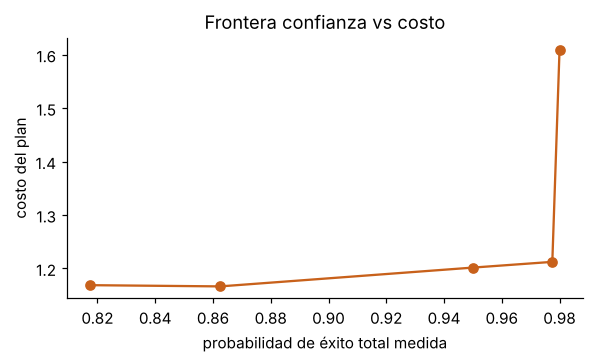

In [10]:
rng = np.random.default_rng(6)
W_search = sample_worlds(X_obs, graphs, 120, rng, **EXPERT)     # versiones con incertidumbre TOTAL para buscar
front, data = [], info["data"]
print("confianza pedida | costo | éxito total medido (400 versiones nuevas) | plan | consultas nuevas")
for eps in [0.50, 0.20, 0.10, 0.05, 0.02]:
    bbf = BlackBox()
    pl, inf = solve_bo(x0, W_search, eps, bbf, n_iter=20, n_cand=700, data=data, seed=int(eps * 100), verbose=False)
    data = inf["data"]                                   # cada corrida reutiliza las consultas de las anteriores
    if pl is None: print(f"      {1 - eps:.2f}       | sin plan dentro de los límites de acción"); continue
    pr = success_prob(margins_real(pl, W_total))[0]
    front.append((1 - eps, plan_cost(pl[None])[0], pr))
    print(f"      {1 - eps:.2f}       | {front[-1][1]:.3f} | {pr:.3f} | HbA1c {pl[0]:+.2f}, Hb {pl[1]:+.2f}, bloqueo={bool(pl[2])} | {bbf.n}")

# Q4 · plan B sin contar con la flecha eGFR -> Hb (incertidumbre estadística, mismo riesgo que el plan principal)
bb4 = BlackBox()
pl4, _ = solve_bo(x0, WORLDS, EPS, bb4, n_iter=20, n_cand=700, data=data, failed_edges=[("eGFR", "Hb")], verbose=False)
if pl4 is not None:
    c4, c1 = plan_cost(pl4[None])[0], plan_cost(plan[None])[0]
    print(f"\nQ4 · plan B sin eGFR->Hb: HbA1c {pl4[0]:+.2f}, Hb {pl4[1]:+.2f}, bloqueo={bool(pl4[2])}, costo {c4:.3f} ({100 * (c4 / c1 - 1):+.1f} % frente al plan principal)")
else: print("\nQ4 · sin eGFR->Hb no hay plan dentro de los límites de acción.")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.plot([f[2] for f in front], [f[1] for f in front], "o-", color="#C8611B")
ax.set(xlabel="probabilidad de éxito total medida", ylabel="costo del plan", title="Frontera confianza vs costo"); plt.tight_layout(); plt.show()

## 11 · Conformal prediction: dónde aplica y dónde no

**Qué hace.** Aplica conformal prediction en las dos capas donde hay respuesta verdadera para calibrar, y arma un presupuesto de error.

| Capa | ¿Hay respuesta verdadera para calibrar? | Qué hace la celda |
|---|---|---|
| 1 · Grafo | No | Conjunto de grafos que acumula 95 % de la frecuencia bootstrap (**no** es garantía formal) |
| 2 · Mecanismos | Sí: cada ecuación es una regresión | Intervalo conformal por mecanismo, y se comprueba su cobertura |
| 3 · Clasificador | Sí: hay etiquetas | Conjunto conformal en el punto al que lleva el plan |

**Literatura**
- [*A Gentle Introduction to Conformal Prediction*](https://arxiv.org/abs/2107.07511) ([Angelopoulos y Bates](https://arxiv.org/abs/2107.07511)): **§1.1** (la receta), **§3.3** (comprobar cobertura), **§4.5** (cambio de covariables).
- [*CONFEX*](https://arxiv.org/abs/2510.19754) (Bilkhoo y otros, 2025): **§3.1** y **§4.1**, exigir conjuntos de una sola clase.
- [*Conformal Selection of Counterfactual Explanations*](https://proceedings.mlr.press/v329/johansson26a.html) ([Johansson y otros](https://proceedings.mlr.press/v329/johansson26a.html), 2026): **§3.1** y trabajo futuro.
- [*Conformal Inference of Counterfactuals and ITE*](https://arxiv.org/abs/2006.06138) (Lei y Candès, 2021): **§3.1–§3.2**.
- [*Partial Causal Structure Learning for Valid Selective Conformal Inference under Interventions*](https://arxiv.org/abs/2603.02204) (Asiaee y otros, 2026). *Solo leímos el resumen.*

**Gap declarado.** [CONFEX](https://arxiv.org/abs/2510.19754) no modela estructura causal y necesita ver el modelo por dentro. [Johansson y otros](https://proceedings.mlr.press/v329/johansson26a.html) dicen que su medida refleja el modelo y no los mecanismos causales, y piden como trabajo futuro medidas de conformidad causales y combinarlas con restricciones de accionabilidad.

**Cómo leer el código.** Split conformal estándar: la mitad de los datos ajusta, la otra mitad calibra, y el cuantil ⌈(n+1)(1−α)⌉/n de los puntajes define el intervalo o el conjunto. El presupuesto suma los errores de las tres capas (cota de unión).

**Advertencias.** (1) Los intervalos por mecanismo valen bajo la distribución observada; al intervenir cambia la distribución de los padres y haría falta la versión ponderada ([Angelopoulos](https://arxiv.org/abs/2107.07511) §4.5). **Eso no está implementado.** (2) La suma es conservadora. (3) La parte del grafo no tiene garantía.

**Qué mirar.** La cobertura comprobada de cada mecanismo, y el conjunto conformal del clasificador después del plan: si contiene las dos clases, el plan de costo mínimo deja al paciente en una zona donde el clasificador duda.

In [11]:
ALPHA_MECH, ALPHA_CLF = 0.05, 0.05
rng = np.random.default_rng(4)
tr, ca = np.arange(0, 150), np.arange(150, 300)          # mitad para ajustar, mitad para calibrar
X_test = sample_world(5000, rng)                         # solo para COMPROBAR la cobertura (en la vida real no existe)

# ---- Capa 2: un intervalo conformal por mecanismo (split conformal sobre los residuos) ----
W_fit = fit_mechanisms(X_obs[tr], g_top)
def mech_pred(X, j):                                     # predicción de la variable j dados sus padres
    b0 = X_obs[tr][:, j].mean() - X_obs[tr].mean(0) @ W_fit[j]
    return b0 + X @ W_fit[j]
print("Capa 2 · intervalos conformales por mecanismo (1 - alfa = %.2f)" % (1 - ALPHA_MECH))
for j in [IDX["eGFR"], IDX["Hb"], IDX["SBP"]]:
    s = np.abs(X_obs[ca][:, j] - mech_pred(X_obs[ca], j))
    q = np.quantile(s, min(1, np.ceil((len(ca) + 1) * (1 - ALPHA_MECH)) / len(ca)))
    cov = np.mean(np.abs(X_test[:, j] - mech_pred(X_test, j)) <= q)
    print(f"  {VARS[j]:<5} ± {q:6.2f}   cobertura comprobada en 5000 casos nuevos: {cov:.3f}")

# ---- Capa 3: conjunto conformal del clasificador en el punto al que lleva el plan ----
X_cal = sample_world(500, rng); y_cal = (rng.random(500) < sigmoid(true_logit(X_cal))).astype(int)
s_cal = 1 - clf.predict_proba(scaler.transform(X_cal))[np.arange(500), y_cal]
q_clf = np.quantile(s_cal, min(1, np.ceil(501 * (1 - ALPHA_CLF)) / 500))
def conformal_set(X): return (1 - clf.predict_proba(scaler.transform(np.atleast_2d(X)))) <= q_clf   # columnas: [no apto, apto]
x_cf = counterfactual(x0, W_point, plan[None])[0, 0]
print("\nCapa 3 · conjunto conformal del clasificador (1 - alfa = %.2f)" % (1 - ALPHA_CLF))
for nm, x in [("paciente hoy", x0), ("después del plan", x_cf)]:
    cs = conformal_set(x)[0]; print(f"  {nm:<17}: {{{', '.join(l for l, k in zip(['no apto', 'apto'], cs) if k)}}}")
cs_all = conformal_set(counterfactual(x0, W_stat, plan[None])[0])
print(f"  versiones donde el conjunto es solo {{apto}}: {np.mean(cs_all[:, 1] & ~cs_all[:, 0]):.2f}")

# ---- Presupuesto de error: una cota conservadora por suma ----
keep_g, mass = [], 0.0
for g, w in graphs:
    keep_g.append(g); mass += w
    if mass >= 0.95: break
alpha1 = 1 - mass
path = [IDX["eGFR"], IDX["Hb"]] + ([] if plan[2] == 1 else [IDX["SBP"]])   # mecanismos que el plan recorre
alpha2 = ALPHA_MECH * len(path)
print("\nPRESUPUESTO DE ERROR (ilustrativo)")
print(f"  capa 1 · grafo fuera del conjunto de {len(keep_g)} grafos:   {alpha1:.3f}  (frecuencia bootstrap, NO es garantía formal)")
print(f"  capa 2 · algún mecanismo del camino ({len(path)} flechas): {alpha2:.3f}")
print(f"  capa 3 · clasificador:                              {ALPHA_CLF:.3f}")
print(f"  suma (cota conservadora del riesgo):                {alpha1 + alpha2 + ALPHA_CLF:.3f}   |   1 - éxito estadístico medido = {1 - p_stat:.3f}")

Capa 2 · intervalos conformales por mecanismo (1 - alfa = 0.95)
  eGFR  ±  15.51   cobertura comprobada en 5000 casos nuevos: 0.943
  Hb    ±   1.62   cobertura comprobada en 5000 casos nuevos: 0.954
  SBP   ±  23.71   cobertura comprobada en 5000 casos nuevos: 0.983

Capa 3 · conjunto conformal del clasificador (1 - alfa = 0.95)
  paciente hoy     : {no apto}
  después del plan : {no apto, apto}
  versiones donde el conjunto es solo {apto}: 0.00

PRESUPUESTO DE ERROR (ilustrativo)
  capa 1 · grafo fuera del conjunto de 6 grafos:   0.050  (frecuencia bootstrap, NO es garantía formal)
  capa 2 · algún mecanismo del camino (2 flechas): 0.100
  capa 3 · clasificador:                              0.050
  suma (cota conservadora del riesgo):                0.200   |   1 - éxito estadístico medido = 0.050


## 12 · Calibración: ¿lo que decimos se cumple?

**Qué hace.** Es la prueba que hace creíble la probabilidad de éxito. Para muchos pacientes y planes compara lo que reportamos (fracción de versiones donde funciona) con lo que pasa en el **mundo verdadero**. Lo hace de dos maneras:

- **(a)** con nuestro único conjunto de datos, que es la situación real;
- **(b)** repitiendo todo con 30 conjuntos de datos distintos del mismo mundo, que es el experimento correcto.

**Literatura**
- [Angelopoulos y Bates](https://arxiv.org/abs/2107.07511): **§3.3**.
- [Posición 2026](https://arxiv.org/abs/2603.28597): **RQ4**.
- [*Selection by Prediction with Conformal p-values*](https://arxiv.org/abs/2210.01408) (Jin y Candès, JMLR 2023). *Pendiente de leer.*

**Gap declarado.** Ningún trabajo de recourse de la línea de Karimi reporta la calibración de su medida de confianza.

**Cómo leer el código.** `calibration_run` solo es posible porque el ejemplo es sintético (`TRUE_WORLD`). La mayoría de los casos caen en 0 o 1; lo informativo son los tramos intermedios.

**Qué mirar.** La diferencia entre (a) y (b). Si (b) está cerca de la diagonal y (a) no, el método es correcto **en promedio**, pero con un solo conjunto de datos el error de estimación es compartido por todos los pacientes. Esa es la razón concreta para añadir una calibración conformal encima.

(a) Un solo conjunto de datos (el nuestro)
  éxito predicho      n    éxito real
    0.00-0.02      586     0.000
    0.02-0.20       26     0.000
    0.20-0.40        8     0.000
    0.40-0.60        9     0.000
    0.80-0.98       27     0.778
    0.98-1.00      540     1.000
  error medio de calibración por tramo: 0.164



(b) Promedio sobre 30 conjuntos de datos
  éxito predicho      n    éxito real
    0.00-0.02     5014     0.000
    0.02-0.20      163     0.061
    0.20-0.40       85     0.294
    0.40-0.60       63     0.413
    0.60-0.80       64     0.672
    0.80-0.98      142     0.951
    0.98-1.00     4069     1.000
  error medio de calibración por tramo: 0.026



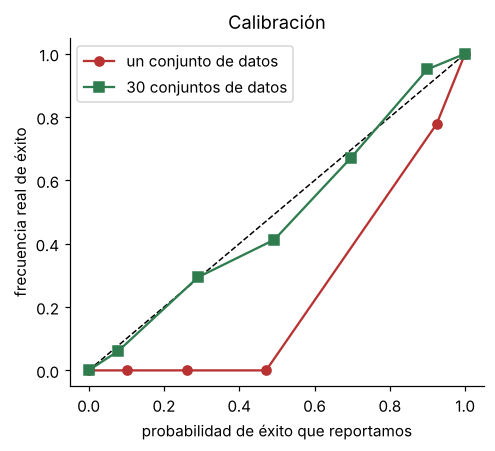

In [12]:
def calibration_run(worlds, rng, n_pat=300, n_plans=4):
    """Para pacientes 'no aptos' y planes al azar: lo que decimos (fracción de versiones) vs lo que pasa
    en el mundo verdadero. Solo es posible porque el ejemplo es sintético."""
    bbc = BlackBox(); pool = sample_world(8 * n_pat, rng); pool = pool[bbc.margin(pool) < -0.5][:n_pat]
    pp, ss = [], []
    for xi in pool:
        P = sample_plans(n_plans, rng)
        Mi = bbc.margin(counterfactual(xi, worlds, P).reshape(-1, 5)).reshape(n_plans, -1)
        pp += list((Mi >= 0).mean(1)); ss += list(bbc.margin(counterfactual(xi, TRUE_WORLD, P)[:, 0, :]) >= 0)
    return np.array(pp), np.array(ss, float)

def reliability(pp, ss, label):
    bins = [0, 0.02, 0.2, 0.4, 0.6, 0.8, 0.98, 1.0001]; xs, ys = [], []
    print(f"{label}\n  éxito predicho      n    éxito real")
    for a, b in zip(bins[:-1], bins[1:]):
        msk = (pp >= a) & (pp < b)
        if msk.sum() >= 5:
            xs.append(pp[msk].mean()); ys.append(ss[msk].mean()); print(f"    {a:.2f}-{min(b, 1):.2f}   {msk.sum():6d}     {ys[-1]:.3f}")
    print(f"  error medio de calibración por tramo: {np.mean(np.abs(np.array(xs) - np.array(ys))):.3f}\n")
    return xs, ys

# (a) Lo que tenemos en la práctica: UN solo conjunto de datos
rng = np.random.default_rng(5)
r1 = reliability(*calibration_run(WORLDS, rng), "(a) Un solo conjunto de datos (el nuestro)")

# (b) El experimento correcto: repetir con 30 conjuntos de datos distintos del mismo mundo
pp_all, ss_all = [], []
for d in range(30):
    Xd = sample_world(300, rng)
    wd = sample_worlds(Xd, bootstrap_graphs(Xd, B=150, rng=rng), 100, rng)
    pp, ss = calibration_run(wd, rng, n_pat=80)
    pp_all.append(pp); ss_all.append(ss)
r2 = reliability(np.concatenate(pp_all), np.concatenate(ss_all), "(b) Promedio sobre 30 conjuntos de datos")

fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.plot(*r1, "o-", color="#B83232", label="un conjunto de datos"); ax.plot(*r2, "s-", color="#2F7D4F", label="30 conjuntos de datos")
ax.set(xlabel="probabilidad de éxito que reportamos", ylabel="frecuencia real de éxito", title="Calibración"); ax.legend(); plt.tight_layout(); plt.show()

## 13 · Resumen y pendientes

La celda siguiente imprime las cifras de esta corrida a partir de las variables del cuaderno.

### Simplificaciones de este MVP

| Pieza | En el MVP | En el paper |
|---|---|---|
| Mecanismos | Lineales | Cualquier modelo de ruido aditivo |
| Grafo | Orden causal dado + pruebas de significancia + bootstrap | Método de descubrimiento causal con incertidumbre |
| Sustituto | Proceso gaussiano de scikit-learn | El de `recourse_bo` |
| Adquisición | Se evalúa sobre candidatos al azar | Se optimiza |
| Paciente | Uno | Muchos, en varios conjuntos de datos |
| Supuestos del experto | Tres probabilidades ilustrativas de 3 % | Elicitados |

### Lo que falta

1. **Comparación contra [NeurIPS 2020](https://arxiv.org/abs/2006.06831)** en su caso de préstamos (validez real, costo, consultas). Sin esto la ventaja es una afirmación.
2. **Q5** (de qué caminos depende el plan, con el juego de Shapley) no está implementada aquí.
3. **Conformal bajo intervención** (versión ponderada) y la **cota por largo de camino**.
4. **Selección por valor p conformal** entre planes candidatos (la idea de [Johansson y otros](https://proceedings.mlr.press/v329/johansson26a.html)).
5. Garantía formal para la capa del grafo.
6. Repetir todo con varias semillas y reportar variabilidad.

In [13]:
print("RESUMEN DE ESTA CORRIDA (ejemplo ilustrativo, una semilla)")
print(f"  Plan ingenuo (una estimación):  costo {plan_cost(naive[None])[0]:.3f} | funciona en {100 * success_prob(BlackBox().margin(counterfactual(x0, WORLDS, naive[None])[0]))[0]:.0f} % de las versiones")
print(f"  Plan robusto (riesgo {EPS:.2f}):      costo {plan_cost(plan[None])[0]:.3f} | HbA1c {plan[0]:+.3f}, Hb {plan[1]:+.2f}, bloqueo={bool(plan[2])}")
print(f"  Consultas: {info['q_search']} de búsqueda + {info['q_cert']} de certificación")
print(f"  Probabilidad de éxito estadística: {p_stat:.3f} | total (con supuestos del experto): {p_total:.3f}")
print("  Frontera (confianza pedida -> costo): " + ", ".join(f"{c:.2f} -> {k:.3f}" for c, k, _ in front))
print(f"  Presupuesto de error por suma: {alpha1 + alpha2 + ALPHA_CLF:.3f}")

RESUMEN DE ESTA CORRIDA (ejemplo ilustrativo, una semilla)
  Plan ingenuo (una estimación):  costo 1.165 | funciona en 61 % de las versiones
  Plan robusto (riesgo 0.10):      costo 1.166 | HbA1c -0.166, Hb +2.00, bloqueo=True
  Consultas: 49 de búsqueda + 120 de certificación
  Probabilidad de éxito estadística: 0.950 | total (con supuestos del experto): 0.848
  Frontera (confianza pedida -> costo): 0.50 -> 1.169, 0.80 -> 1.166, 0.90 -> 1.202, 0.95 -> 1.212, 0.98 -> 1.609
  Presupuesto de error por suma: 0.200


## Referencias con enlace

Los enlaces de este cuaderno se comprobaron el 2026-11-13: título y autores contra la API de arXiv, contra Crossref (el survey) o contra el índice del volumen 329 de PMLR (Johansson y otros). Lo comprobado es que cada enlace lleva al artículo indicado. Las secciones citadas (por ejemplo "§4.1"), las frases atribuidas a cada artículo y las sedes de publicación que el cuaderno menciona no se cotejaron en esta revisión.

- Karimi, Schölkopf, Valera. *Algorithmic Recourse: from Counterfactual Explanations to Interventions* ("MINT", "FAccT 2021" en este cuaderno). <https://arxiv.org/abs/2002.06278>
- Karimi, von Kügelgen, Schölkopf, Valera. *Algorithmic recourse under imperfect causal knowledge: a probabilistic approach* ("NeurIPS 2020" en este cuaderno). <https://arxiv.org/abs/2006.06831>
- Karimi, Barthe, Schölkopf, Valera. *A Survey of Algorithmic Recourse: Contrastive Explanations and Consequential Recommendations*. ACM Computing Surveys, 2022 ("el survey"). Versión de arXiv, con otro subtítulo (*definitions, formulations, solutions, and prospects*): <https://arxiv.org/abs/2010.04050>. DOI: <https://doi.org/10.1145/3527848>
- Dominguez-Olmedo, Karimi, Schölkopf. *On the Adversarial Robustness of Causal Algorithmic Recourse* ("ICML 2022" en este cuaderno). <https://arxiv.org/abs/2112.11313>
- Padh, Li, Casolo, Kilbertus. *Your Assumed DAG is Wrong and Here's How To Deal With It*. arXiv, 2025. <https://arxiv.org/abs/2502.17030>
- Wang, Kolar, Drton. *Confidence Sets for Causal Orderings*. arXiv, 2023. <https://arxiv.org/abs/2305.14506>
- Lorch, Rothfuss, Schölkopf, Krause. *DiBS: Differentiable Bayesian Structure Learning*. arXiv, 2021. <https://arxiv.org/abs/2105.11839>
- Toth, Lorch, Knoll, Krause, Pernkopf, Peharz y otros. *Active Bayesian Causal Inference*. arXiv, 2022. <https://arxiv.org/abs/2206.02063>
- Karimi. *Position: Explainable AI is Causality in Disguise*. arXiv, 2026 ("posición 2026" en este cuaderno). <https://arxiv.org/abs/2603.28597>
- Cakmak, Astudillo, Frazier, Zhou. *Bayesian Optimization of Risk Measures*. arXiv, 2020 (el cuaderno abrevia el título como "BO of Risk Measures"). <https://arxiv.org/abs/2007.05554>
- Astudillo, Frazier. *Bayesian Optimization of Composite Functions*. ICML 2019, PMLR 97:354-363. <https://arxiv.org/abs/1906.01537>
- Gelbart, Snoek, Adams. *Bayesian Optimization with Unknown Constraints*. arXiv, 2014. <https://arxiv.org/abs/1403.5607>
- Afroogh y otros. *Beyond Explainable AI (XAI): An Overdue Paradigm Shift and Post-XAI Research Directions*. arXiv, 2026. <https://arxiv.org/abs/2602.24176>
- Angelopoulos, Bates. *A Gentle Introduction to Conformal Prediction and Distribution-Free Uncertainty Quantification*. arXiv, 2021. <https://arxiv.org/abs/2107.07511>
- Bilkhoo, Hosseini, Kazemi, Paoletti. *CONFEX: Uncertainty-Aware Counterfactual Explanations with Conformal Guarantees*. arXiv, 2025. <https://arxiv.org/abs/2510.19754>
- Johansson, Maalej, Ståhl, Boström. *Conformal Selection of Counterfactual Explanations: From Minimal to Robust Recourse*. COPA 2026, PMLR 329:529-547. <https://proceedings.mlr.press/v329/johansson26a.html>
- Lei, Candès. *Conformal Inference of Counterfactuals and Individual Treatment Effects*. arXiv, 2020 (el cuaderno abrevia "ITE" y lo fecha en 2021). <https://arxiv.org/abs/2006.06138>
- Asiaee, Aryan, Long. *Partial Causal Structure Learning for Valid Selective Conformal Inference under Interventions*. arXiv, 2026. <https://arxiv.org/abs/2603.02204>
- Jin, Candès. *Selection by Prediction with Conformal p-values*. arXiv, 2022. <https://arxiv.org/abs/2210.01408>
